# Flux: wet nights of the LI-7200 NEE (2016-2025)

# About this notebook

The open-path LI-7500 (`IRGA75`) loses most wet nights: rain, dew and fog wet its windows and raise
its AGC, and those half-hours are discarded. Gap-filling and the night-time partitioning then treat the
missing nights like the measured dry ones. On the nights that only the enclosed-path LI-7200
(`IRGA72`) measured in 2016-2017, its night-time `NEE` is 1 to 3 µmol m⁻² s⁻¹ higher than on dry
nights at the same air temperature, and the gap-filled LI-7500 `RECO` and `GPP` come out 140 to
360 gC m⁻² per year below those of the LI-7200.

This notebook asks whether that excess is real, using the LI-7200 record 2016-2025. It compares the
night-time `NEE` of wet and dry nights at the same temperature, and checks timing after rain, the
storage term, the sonic anemometer, the LI-7200 diagnostics and, in 2016-2017, the LI-7500. It
computes no product and changes nothing in the flux chain. The background is in
[`FLUX_NEE_IRGA75_EVALUATION`](FLUX_NEE_IRGA75_EVALUATION.ipynb).

# Main findings

- **Size.** On the night half-hours with `NEE` after Level 3.3, the LI-7200 measures more than the
  dry-night reference in every wet class on average and in most years 2016-2025: during rain
  0.9 µmol m⁻² s⁻¹ on average (0.2 to 1.6 per year), on fog/dew nights 1.1 (-0.3 to 2.5), on humid
  nights 1.1 (-0.2 to 2.2) and after rain 0.3 (-0.2 to 1.0). With other references (soil
  temperature, another E0, no model) it is between about 0.4 and 1.7 times as large; after rain it
  is close to zero with some of them.
- **Per year.** The nights with RH of at least 98 %, 31-42 % of all night half-hours, carry 30 to
  118 gC m⁻² per year above the dry-night reference.
- **Driver: air humidity, not rain.** The excess rises with RH also when there was no rain within
  24 hours, from -0.3 below 70 % to +1.1 at 98 % and above. With RH in a linear model, the
  coefficients of rain and of the hours after rain are negative (-0.3 and -0.6). There is no pulse
  after rain: during an event the excess stays at 0.7-0.9 from the first hour on, and after rain it
  follows RH, not the time since rain. It is largest from June to October and on dry soil (1.2 in
  the driest fifth of the soil water content, 0.1 in the wettest).
- **Not storage.** The excess sits in the turbulent flux. The storage term is 0.0 to 0.1 lower on
  wet nights than on dry ones. After calm spells the excess is smaller in three of the five
  classes, but larger on humid nights and during rain.
- **Sonic.** Wet nights show signs of a wet sonic: positive `H`, more steady-state failures of
  `H`, more spikes in rain, and a sonic temperature about 4-9 K above `TA` against 3 K on dry nights.
  Without these half-hours the difference to the dry nights remains 0.6-1.0 in rain and 1.0-1.8 on
  fog/dew nights, and the excess shows no consistent trend with the sonic temperature.
- **LI-7200.** The excess is higher at signal strength below 80 % (rain 1.4 against 0.4 at 95 %
  and above, fog/dew 2.9 against 0.6), and part of it remains at full signal. The flow has no
  effect.
- **LI-7500.** Where the LI-7500 is clean (AGC at most 50), its corrected flux also shows an excess
  on humid nights (1.0 against 0.7 of the LI-7200), and after rain neither shows one (-0.2 against
  -0.3). On fog/dew nights the two disagree (-3.1 against +1.2, correlation 0.3). Only 7 clean
  LI-7500 half-hours fall in rain.
- **Verdict.** The excess is not a storage effect and not a rain pulse, and the signal strength of
  the LI-7200 explains only part of it. It is most likely a real flux of humid and saturated
  nights. A fault of the shared sonic and a dry-night reference that is itself too low cannot be
  ruled out.

</br>

# Settings

In [1]:
from pathlib import Path

DATADIR = Path(r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow")
FILE_NEE72 = r"30_FLUX_POST-PROCESSING_CHAIN\IRGA72\05_FPPC_IRGA72_NEE_2016-2026.09.parquet"
FILE_L1_72 = r"20_L1_FLUXES\IRGA72\99_IRGA72_L1_MERGED_2016-2026.09.parquet"
FILE_OPCO75 = r"30_FLUX_POST-PROCESSING_CHAIN\IRGA75\01_FPPC_IRGA75_OPEN-PATH_CORRECTION_2004-2017_2019.parquet"
FILE_METEO = r"10_METEO\30_PRODUCTS\99_METEO_MERGED_2004-2026.09.parquet"

# The merged meteo has no precipitation after 2025, so the wetness classes end there.
FIRST_DAY, LAST_DAY = '2016-01-01', '2025-12-31 23:59'

# Night-time NEE after Level 3.3: quality flags 0 and 1 (QCF), USTAR scenario CUT_50.
NEE = 'NEE_L3.1_L3.3_CUT_50_QCF'
NEE_VARIANTS = {'CUT_50, flag 0 only': 'NEE_L3.1_L3.3_CUT_50_QCF0',
                'CUT_16': 'NEE_L3.1_L3.3_CUT_16_QCF', 'CUT_84': 'NEE_L3.1_L3.3_CUT_84_QCF'}
NEE_L31, SC, FC_L2 = 'NEE_L3.1', 'SC_SINGLE_gfRMED_L3.1', 'FC_L2_QCF'
USTAR_FLAG = 'FLAG_L3.3_CUT_50_NEE_L3.1_USTAR_TEST'
E0_NT = 'E0_NT_OF_CUT_50'  # temperature sensitivity of the night-time partitioning, one value per year
L1_COLS = ['H', 'H_SSITC_TEST', 'USTAR', 'ZL', 'WS', 'T_SONIC', 'W_NUM_SPIKES', 'T_SONIC_NUM_SPIKES',
           'SONIC_DIAG_NREX', 'CUSTOM_SIGNAL_STRENGTH_IRGA72_MEAN', 'CUSTOM_FLOW_VOLRATE_MEAN']
OPCO75_COLS = ['FC_L1.1_OPCO', 'FC_SSITC_TEST', 'CUSTOM_AGC_IRGA75_MEAN']
METEO_COLS = {'TA_T1_47_1_HOMOGENIZED_gfXG': 'TA', 'SW_IN_T1_47_1_gfXG': 'SW_IN',
              'PREC_TOT_T1_47_1_HOMOGENIZED': 'PREC', 'RH_T1_47_1_HOMOGENIZED': 'RH',
              'LW_IN_T1_47_1': 'LW_IN', 'TS_FF1_0.05_HOMOGENIZED_GAPFILLED': 'TS_5CM',
              'SWC_FF1_0.05_1_HOMOGENIZED': 'SWC_5CM'}

NIGHT_SW_IN = 10        # W m-2: night is SW_IN below this
EVENT_GAP_HH = 4        # rain half-hours separated by up to 2 h of no rain belong to one event
AFTER_RAIN_H = 24       # hours after the end of an event that count as "after rain"
RH_DRY, RH_FOG = 90, 98  # %
AGC_LIMIT = 50          # LI-7500 AGC of a clean window (the flux chain keeps 40 to 65)

# Reference of the dry nights: Lloyd-Taylor (Tref 10 C, T0 -46.02 C) with E0 of the year, and a
# reference respiration per day from the dry nights within +-7 days, widened to +-15 and +-30 days
# when fewer than REF_MIN_RECORDS are found.
TREF, T0 = 10.0, -46.02
REF_WINDOWS, REF_MIN_RECORDS = (7, 15, 30), 20

CLASSES = ['dry', 'humid', 'fog/dew', 'after rain', 'rain']
GC = 12.011e-6 * 1800  # umol m-2 s-1 in one half-hour -> gC m-2

# Imports

In [2]:
import importlib.metadata
import textwrap
import warnings
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings(action='ignore', category=FutureWarning)
warnings.filterwarnings(action='ignore', category=RuntimeWarning)
NOTEBOOK_START = datetime.now()
print(f"Last run: {NOTEBOOK_START:%Y-%m-%d %H:%M:%S}")
for _p in ('pandas', 'numpy'):
    print(f"{_p} version: v{importlib.metadata.version(_p)}")

Last run: 2026-11-04 17:34:50
pandas version: v3.0.3
numpy version: v2.4.6


# Helpers

In [3]:
def tabcap(text, width=100):
    """Print a table caption. Called by `styled`, so no table can be shown without one."""
    print(textwrap.fill(f"Table — {text}", width) + "\n")


def figcap(fig, text, width=125):
    """Place a caption under a figure drawn with a layout engine. Call after the last axes."""
    width = min(width, max(40, int(14.5 * fig.get_size_inches()[0])))
    fig.supxlabel(textwrap.fill(f"Figure — {text}", width), fontsize=9, ha='left', x=0.005)


def styled(data, caption, fmt="{:.2f}", subset=None, cmap="RdBu_r", axis=None, center=True):
    """`data` as a table with a caption, fixed decimals and a colour scale over its values."""
    numeric = [c for c in data.columns if pd.api.types.is_numeric_dtype(data[c])]
    fmt = {c: fmt for c in numeric} if isinstance(fmt, str) else {
        c: fmt.get(c, "{:.2f}") for c in numeric}
    tabcap(caption)
    styler = data.style.format(fmt, na_rep="-")
    if cmap is None or not numeric:
        return styler
    values = data.loc[subset] if isinstance(subset, tuple) else (
        data[subset] if subset is not None else data[numeric])
    limits = {}
    if center:
        absmax = np.nanmax(np.abs(values.to_numpy(dtype=float)))
        limits = dict(vmin=-absmax, vmax=absmax)
    return styler.background_gradient(cmap=cmap, subset=subset, axis=axis,
                                      text_color_threshold=0.4, **limits)


def lloyd_taylor(t, e0):
    """Lloyd-Taylor temperature function, 1 at TREF."""
    return np.exp(e0 * (1.0 / (TREF - T0) - 1.0 / (t - T0)))


def dry_reference(frame, col, temp='TA', e0=None):
    """Expected night NEE from the dry nights at the temperature of each record.

    Per year: E0 of the year (or `e0`), and a reference respiration per day fitted to the dry
    nights within the narrowest window of REF_WINDOWS that holds REF_MIN_RECORDS of them.
    """
    out = pd.Series(np.nan, index=frame.index)
    for _yr, g in frame.groupby('year'):
        if g[temp].notna().sum() == 0:
            continue
        e = g[E0_NT].median() if e0 is None else e0
        fit = (g['cls'] == 'dry') & g[col].notna() & g[temp].notna()
        y, f, day = g.loc[fit, col].to_numpy(), lloyd_taylor(g.loc[fit, temp], e).to_numpy(), g.loc[fit, 'day'].to_numpy()
        rref = {}
        for dd in np.unique(g['day']):
            for half in REF_WINDOWS:
                w = np.abs(day - dd) <= half
                if w.sum() >= REF_MIN_RECORDS:
                    rref[dd] = (y[w] * f[w]).sum() / (f[w] ** 2).sum()
                    break
        out.loc[g.index] = g['day'].map(rref).astype(float) * lloyd_taylor(g[temp], e)
    return out


def by_class(s, values, agg=('size', 'mean', 'median')):
    """`values` of the frame `s` aggregated per wetness class, in class order."""
    return s.groupby('cls', observed=True)[values].agg(list(agg)).reindex(CLASSES)


def binned(s, by, bins, values='ex', cols='cls'):
    """Mean of `values` per bin of `by` (rows) and class (columns), and the counts."""
    b = pd.cut(s[by], bins)
    mean = s.pivot_table(index=b, columns=cols, values=values, aggfunc='mean', observed=True)
    n = s.pivot_table(index=b, columns=cols, values=values, aggfunc='size', observed=True)
    return mean, n

</br>

# Load data

In [4]:
_files = {'IRGA72 NEE (05)': DATADIR / FILE_NEE72, 'IRGA72 Level 1': DATADIR / FILE_L1_72,
          'IRGA75 with opco (01)': DATADIR / FILE_OPCO75, 'meteo, merged': DATADIR / FILE_METEO}
_nee_cols = [NEE, *NEE_VARIANTS.values(), NEE_L31, SC, FC_L2, USTAR_FLAG, E0_NT]
n72 = pd.read_parquet(_files['IRGA72 NEE (05)'], columns=_nee_cols)
l1 = pd.read_parquet(_files['IRGA72 Level 1'], columns=L1_COLS)
o75 = pd.read_parquet(_files['IRGA75 with opco (01)'], columns=OPCO75_COLS).loc['2016':'2017']
met = pd.read_parquet(_files['meteo, merged'], columns=list(METEO_COLS)).rename(columns=METEO_COLS)
d = n72.join(l1).join(met).loc[FIRST_DAY:LAST_DAY].copy()
print(f"{len(d):,} half-hours from {d.index[0]} to {d.index[-1]}")

175,344 half-hours from 2016-01-01 00:15:00 to 2025-12-31 23:45:00


## 📋 Table: input files and the run they come from

In [5]:
_inputs = pd.DataFrame({
    'file': [p.name for p in _files.values()],
    'modified': [f"{datetime.fromtimestamp(p.stat().st_mtime):%Y-%m-%d %H:%M}" for p in _files.values()],
}, index=list(_files))
display(styled(_inputs, caption="the input files with their modification time. The numbers in this notebook "
                                "belong to the runs of these dates", cmap=None))

Table — the input files with their modification time. The numbers in this notebook belong to the
runs of these dates



,file,modified
IRGA72 NEE (05),05_FPPC_IRGA72_NEE_2016-2026.09.parquet,2026-11-04 15:46
IRGA72 Level 1,99_IRGA72_L1_MERGED_2016-2026.09.parquet,2026-10-25 02:04
IRGA75 with opco (01),01_FPPC_IRGA75_OPEN-PATH_CORRECTION_2004-2017_2019.parquet,2026-11-04 11:31
"meteo, merged",99_METEO_MERGED_2004-2026.09.parquet,2026-10-29 21:02


## Integrity checks

In [6]:
_issues = []
for _name, _df in (('IRGA72 05', n72), ('IRGA72 L1', l1), ('IRGA75 01', o75), ('meteo', met)):
    if _df.index.duplicated().any():
        _issues.append(f"{_name}: duplicate timestamps")
if not (d.index.to_series().diff().dropna() == pd.Timedelta('30min')).all():
    _issues.append("the joined frame has index gaps")
if d['PREC'].isna().any():
    _issues.append(f"precipitation is missing in {d['PREC'].isna().sum()} half-hours")
if d['SONIC_DIAG_NREX'].fillna(0).ne(0).any():
    _issues.append("SONIC_DIAG_NREX is no longer always 0; use it in the sonic checks")
assert not _issues, "the inputs are not what this notebook assumes: " + "; ".join(_issues)
print("Integrity checks passed. SONIC_DIAG_NREX is 0 in every half-hour and carries no information.")

Integrity checks passed. SONIC_DIAG_NREX is 0 in every half-hour and carries no information.


</br>

# Wetness classes

A night half-hour falls into the first class that applies:

- **rain**: inside a rain event, from its first to its last half-hour with precipitation; dry
  spells of up to 2 hours inside an event are part of it.
- **after rain**: up to 24 hours after the end of an event.
- **fog/dew**: no rain within 24 hours, RH at least 98 %.
- **humid**: no rain within 24 hours, RH 90 to 98 %.
- **dry**: no rain within 24 hours, RH below 90 %.

Night is `SW_IN` below 10 W m⁻². The excess is the measured `NEE` minus the dry-night reference
(see Settings): the `NEE` that the dry nights of the same weeks give at the air temperature of the
half-hour. By construction it is about zero on dry nights.

In [7]:
_rain = d['PREC'] > 0
_i = np.arange(len(d))
_last = pd.Series(np.where(_rain, _i, np.nan), index=d.index).ffill()
_gap = _i - _last.shift(1).to_numpy()
_start = _rain & ((_gap > EVENT_GAP_HH) | np.isnan(_gap))
_ev = _start.cumsum().where(_rain)
_in_event = (_ev.ffill() == _ev.bfill()) & _ev.ffill().notna()
_t_start = pd.Series(np.where(_start, _i, np.nan), index=d.index).ffill()
d['in_event'] = _in_event
d['h_since_start'] = np.where(_in_event, (_i - _t_start) / 2, np.nan)
d['h_since_stop'] = np.where(_in_event, np.nan, (_i - _last.to_numpy()) / 2)
d['cls'] = pd.Categorical(np.select(
    [_in_event, d['h_since_stop'] <= AFTER_RAIN_H, d['RH'] >= RH_FOG, d['RH'] >= RH_DRY, d['RH'] < RH_DRY],
    ['rain', 'after rain', 'fog/dew', 'humid', 'dry'], default='unknown'), CLASSES)
d['rain_state'] = np.where(d['cls'] == 'rain', 'rain', np.where(d['cls'] == 'after rain', 'after rain', 'no rain in 24 h'))

# rain events: amount, and days without rain before them
_e = pd.DataFrame({'ev': _ev, 'p': d['PREC'], 't': d.index}).dropna(subset=['ev'])
_eg = _e.groupby('ev')
_cur = _ev.ffill().where(_in_event | (d['h_since_stop'] <= AFTER_RAIN_H))
d['event_mm'] = _cur.map(_eg['p'].sum())
d['days_dry_before'] = _cur.map((_eg['t'].first() - _eg['t'].last().shift(1)).dt.total_seconds() / 86400)

d['year'] = d.index.year
d['day'] = (d.index - pd.Timestamp(FIRST_DAY)).days
d['night'] = d['SW_IN'] < NIGHT_SW_IN
d['cloud'] = d['LW_IN'] / (5.67e-8 * (d['TA'] + 273.15) ** 4)  # LW_IN over clear-air emission at TA
d['FC_turb'] = (d[NEE_L31] - d[SC]).where(d[NEE].notna())
# a u* failure in the 2 hours before: the first half-hours after a calm spell
d['calm_before'] = d[USTAR_FLAG].eq(2).astype(float).shift(1).rolling(4, min_periods=1).max().eq(1)

dn_all = d[d['night']].copy()
dn_all['ref'] = dry_reference(dn_all, NEE)
dn_all['ex'] = dn_all[NEE] - dn_all['ref']
dn = dn_all[dn_all[NEE].notna()].copy()
print(f"{len(dn_all):,} night half-hours, {len(dn):,} with NEE after Level 3.3")

91,863 night half-hours, 18,636 with NEE after Level 3.3


## 📋 Table: wetness classes

In [8]:
_t = pd.DataFrame({
    'night share (%)': dn_all['cls'].value_counts(normalize=True).reindex(CLASSES) * 100,
    'measured (%)': dn.groupby('cls', observed=True).size().reindex(CLASSES)
                    / dn_all.groupby('cls', observed=True).size().reindex(CLASSES) * 100,
    'TA (°C)': dn.groupby('cls', observed=True)['TA'].mean(),
    'RH (%)': dn.groupby('cls', observed=True)['RH'].median(),
    'USTAR (m s-1)': dn.groupby('cls', observed=True)['USTAR'].median(),
    'cloudiness': dn.groupby('cls', observed=True)['cloud'].median(),
})
display(styled(_t, caption="share of all night half-hours 2016-2025 per class, the share with NEE after "
                           "Level 3.3, and the median conditions of the measured ones. Cloudiness is LW_IN "
                           "over the emission of clear air at TA (about 0.8 clear, 1 overcast)", cmap=None,
               fmt={'night share (%)': "{:.1f}", 'measured (%)': "{:.1f}", 'TA (°C)': "{:.1f}", 'RH (%)': "{:.0f}",
                    'USTAR (m s-1)': "{:.2f}", 'cloudiness': "{:.2f}"}))

Table — share of all night half-hours 2016-2025 per class, the share with NEE after Level 3.3, and
the median conditions of the measured ones. Cloudiness is LW_IN over the emission of clear air at TA
(about 0.8 clear, 1 overcast)



,night share (%),measured (%),TA (°C),RH (%),USTAR (m s-1),cloudiness
cls,,,,,,
dry,34.7,20.8,11.7,69,0.73,0.77
humid,6.8,22.9,4.6,94,0.74,0.87
fog/dew,8.4,13.3,0.7,100,0.72,0.97
after rain,37.2,18.4,6.1,96,0.73,0.94
rain,12.9,27.5,7.3,100,0.80,0.99


</br>

# 1. Size of the excess per class and year

## 📋 Table: excess per class

In [9]:
_t = by_class(dn, 'ex').rename(columns={'size': 'n'})
_t['trimmed mean'] = dn.groupby('cls', observed=True)['ex'].apply(
    lambda x: x[(x > x.quantile(.05)) & (x < x.quantile(.95))].mean())
_t['NEE'] = dn.groupby('cls', observed=True)[NEE].mean()
_t['reference'] = dn.groupby('cls', observed=True)['ref'].mean()
display(styled(_t, caption="excess of the night NEE over the dry-night reference per class, in µmol m⁻² s⁻¹, "
                           "2016-2025. The trimmed mean leaves out the lowest and highest 5 %",
               fmt={'n': "{:.0f}"}, subset=['mean', 'median', 'trimmed mean']))

Table — excess of the night NEE over the dry-night reference per class, in µmol m⁻² s⁻¹, 2016-2025.
The trimmed mean leaves out the lowest and highest 5 %



,n,mean,median,trimmed mean,NEE,reference
cls,,,,,,
dry,6647,0.07,-0.37,-0.07,4.89,4.81
humid,1419,1.06,0.44,0.87,4.27,3.39
fog/dew,1023,1.11,0.14,0.89,3.86,2.79
after rain,6284,0.30,-0.21,0.13,4.02,3.79
rain,3263,0.87,0.28,0.75,4.99,4.13


## 📋 Table: mean excess per year and class

In [10]:
_t = dn.pivot_table(index='year', columns='cls', values='ex', aggfunc='mean', observed=True)[CLASSES]
_t['E0 (K)'] = dn.groupby('year')[E0_NT].median()
display(styled(_t, caption="mean excess per year and class, in µmol m⁻² s⁻¹, with the E0 of the year "
                           "from the night-time partitioning of the chain", subset=CLASSES,
               fmt={**{c: "{:.2f}" for c in CLASSES}, 'E0 (K)': "{:.0f}"}))

Table — mean excess per year and class, in µmol m⁻² s⁻¹, with the E0 of the year from the night-time
partitioning of the chain



cls,dry,humid,fog/dew,after rain,rain,E0 (K)
year,,,,,,
2016,-0.03,1.09,1.86,0.48,1.35,105
2017,0.02,0.47,1.43,-0.14,0.68,98
2018,0.10,0.87,1.77,0.96,1.55,175
2019,0.04,1.90,-0.28,-0.00,0.37,112
2020,0.11,1.17,0.59,0.69,1.32,133
2021,0.11,1.23,2.53,0.08,0.90,144
2022,0.11,-0.18,0.96,0.44,0.23,138
2023,0.13,0.72,-0.02,0.24,1.31,151
2024,-0.04,2.19,1.76,0.58,0.78,125


## 📋 Table: excess per class with other choices

In [11]:
_rob = {'main (CUT_50, TA, E0 of the year)': dn.groupby('cls', observed=True)['ex'].mean()}
for _name, _col in NEE_VARIANTS.items():
    _e = dn_all[_col] - dry_reference(dn_all, _col)
    _rob[_name] = _e[dn_all[_col].notna()].groupby(dn_all['cls'], observed=True).mean()
_e = dn_all[NEE] - dry_reference(dn_all, NEE, temp='TS_5CM')
_rob['soil temperature 5 cm'] = _e[dn_all[NEE].notna()].groupby(dn_all['cls'], observed=True).mean()
for _e0 in (50.0, 250.0):
    _e = dn_all[NEE] - dry_reference(dn_all, NEE, e0=_e0)
    _rob[f'E0 = {_e0:.0f} K'] = _e[dn_all[NEE].notna()].groupby(dn_all['cls'], observed=True).mean()
# without a model: the mean NEE of the dry nights within +-7 days and +-1 K
_dry = dn[dn['cls'] == 'dry']
_dd, _tt, _yy = _dry['day'].to_numpy(), _dry['TA'].to_numpy(), _dry[NEE].to_numpy()
_an = []
for _day, _ta in zip(dn['day'].to_numpy(), dn['TA'].to_numpy()):
    _w = (np.abs(_dd - _day) <= 7) & (np.abs(_tt - _ta) <= 1)
    _an.append(_yy[_w].mean() if _w.sum() >= 5 else np.nan)
dn['ex_analogue'] = dn[NEE] - np.array(_an)
_rob['analogue, ±7 days and ±1 K'] = dn.groupby('cls', observed=True)['ex_analogue'].mean()
_t = pd.DataFrame(_rob).reindex(CLASSES)
display(styled(_t, caption="mean excess per class in µmol m⁻² s⁻¹ for other flag levels, USTAR scenarios, "
                           "temperature drivers and E0, and without a model (the dry nights within ±7 days "
                           "and ±1 K, at least 5 of them)"))

Table — mean excess per class in µmol m⁻² s⁻¹ for other flag levels, USTAR scenarios, temperature
drivers and E0, and without a model (the dry nights within ±7 days and ±1 K, at least 5 of them)



,"main (CUT_50, TA, E0 of the year)","CUT_50, flag 0 only",CUT_16,CUT_84,soil temperature 5 cm,E0 = 50 K,E0 = 250 K,"analogue, ±7 days and ±1 K"
cls,,,,,,,,
dry,0.07,0.05,0.08,0.12,0.01,0.01,0.24,0.01
humid,1.06,1.29,1.01,0.95,0.75,0.83,1.49,0.60
fog/dew,1.11,1.12,1.22,1.38,0.62,0.78,1.63,0.77
after rain,0.30,0.15,0.32,0.13,-0.10,-0.03,0.83,-0.21
rain,0.87,0.54,1.14,0.55,0.49,0.57,1.45,0.33


## 📋 Table: what the excess adds to the night per year

In [12]:
_n_all = dn_all.groupby(['year', 'cls'], observed=True).size()
_mean = dn.groupby(['year', 'cls'], observed=True)['ex'].mean()
_t = (_mean * _n_all * GC).unstack()[CLASSES]
_sat = dn['RH'] >= RH_FOG
_t['RH ≥ 98 %, any class'] = (dn[_sat].groupby('year')['ex'].mean()
                              * dn_all[dn_all['RH'] >= RH_FOG].groupby('year').size() * GC)
_t['RH ≥ 98 %, share of night (%)'] = (dn_all['RH'] >= RH_FOG).groupby(dn_all['year']).mean() * 100
display(styled(_t, caption="mean excess of a class times the number of all its night half-hours, in gC m⁻² "
                           "per year: what the nights of a class carry above the dry-night reference. The "
                           "last two columns take the nights with RH of at least 98 % together, the nights "
                           "the LI-7500 loses most",
               fmt="{:.0f}", subset=CLASSES + ['RH ≥ 98 %, any class']))

Table — mean excess of a class times the number of all its night half-hours, in gC m⁻² per year:
what the nights of a class carry above the dry-night reference. The last two columns take the nights
with RH of at least 98 % together, the nights the LI-7500 loses most



cls,dry,humid,fog/dew,after rain,rain,"RH ≥ 98 %, any class","RH ≥ 98 %, share of night (%)"
year,,,,,,,
2016,-2,18,30,34,37,118,36
2017,2,5,30,-10,16,46,40
2018,8,17,29,64,33,87,33
2019,3,17,-4,-0,10,38,34
2020,8,14,9,46,33,67,32
2021,7,17,47,6,23,75,40
2022,8,-2,13,33,6,40,31
2023,9,7,-0,20,36,36,31
2024,-2,34,39,48,23,76,42


The excess is present in every wet class and in most years. Its size depends on the reference:
soil temperature, a low E0 or the analogue method give less, a high E0 gives more. After rain it
is small with every choice but the high E0. The yearly sums assume that the measured half-hours of a class stand
for all half-hours of that class.

</br>

# 2. Timing after rain and what drives the excess

## 📋 Table: excess during rain by hours since the start of the event

In [13]:
_s = dn[dn['cls'] == 'rain']
_t = _s.groupby(pd.cut(_s['h_since_start'], [-0.1, 2, 6, 12, 1000]), observed=True)['ex'].agg(['size', 'mean', 'median'])
_t.index = ['0-2 h', '2-6 h', '6-12 h', 'over 12 h']
display(styled(_t.rename(columns={'size': 'n'}), caption="excess during rain events by hours since the event "
                                                         "started, in µmol m⁻² s⁻¹", fmt={'n': "{:.0f}"},
               subset=['mean', 'median']))

Table — excess during rain events by hours since the event started, in µmol m⁻² s⁻¹



,n,mean,median
0-2 h,1401,0.84,0.39
2-6 h,1022,0.91,0.23
6-12 h,625,0.92,0.28
over 12 h,215,0.74,-0.17


## 📋 Table: excess by hours since the end of rain and RH

In [14]:
_s = dn[dn['h_since_stop'].notna()].copy()
_s['RH class'] = pd.cut(_s['RH'], [0, RH_DRY, RH_FOG, 101], labels=['RH < 90 %', 'RH 90-98 %', 'RH ≥ 98 %'], right=False)
_bins, _labels = [0, 3, 6, 12, 24, 48, 96, 1e5], ['0-3 h', '3-6 h', '6-12 h', '12-24 h', '1-2 d', '2-4 d', 'over 4 d']
_s['since'] = pd.cut(_s['h_since_stop'], _bins, labels=_labels)
timing = _s.pivot_table(index='since', columns='RH class', values='ex', aggfunc='mean', observed=True)
timing['all'] = _s.groupby('since', observed=True)['ex'].mean()
timing['n'] = _s.groupby('since', observed=True).size()
display(styled(timing, caption="excess by hours since the end of the last rain event, for all RH and split by "
                               "RH, in µmol m⁻² s⁻¹", fmt={'n': "{:.0f}"}, subset=list(timing.columns[:-1])))

Table — excess by hours since the end of the last rain event, for all RH and split by RH, in µmol
m⁻² s⁻¹



RH class,RH < 90 %,RH 90-98 %,RH ≥ 98 %,all,n
since,,,,,
0-3 h,-0.77,-0.07,0.53,0.21,1873
3-6 h,-0.81,0.40,0.28,0.06,1003
6-12 h,-0.12,0.33,0.49,0.20,1225
12-24 h,0.16,0.68,1.15,0.53,2183
1-2 d,0.07,0.80,1.10,0.31,2720
2-4 d,0.08,1.10,0.37,0.26,2693
over 4 d,0.07,1.29,1.71,0.36,3676


## 📊 Plot: excess by hours since the end of rain

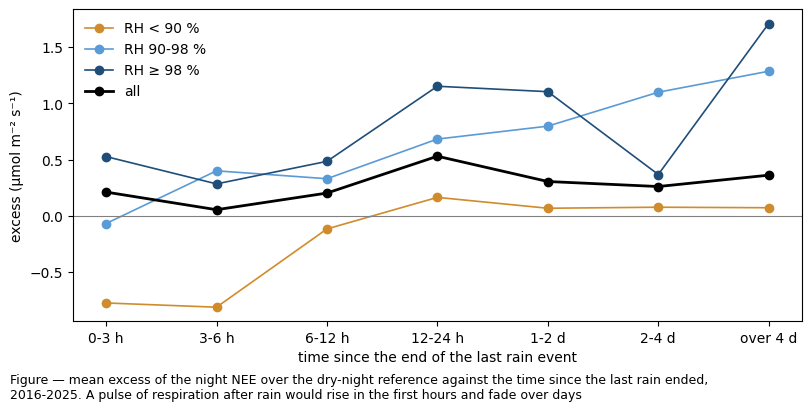

In [15]:
fig, ax = plt.subplots(figsize=(8, 4), layout='constrained')
_x = np.arange(len(timing))
for _col, _c in zip(['RH < 90 %', 'RH 90-98 %', 'RH ≥ 98 %', 'all'], ['#d08c2c', '#5b9bd5', '#1f4e79', 'k']):
    ax.plot(_x, timing[_col], marker='o', color=_c, label=_col, lw=2 if _col == 'all' else 1.2)
ax.axhline(0, color='0.5', lw=0.8)
ax.set_xticks(_x, timing.index)
ax.set_ylabel('excess (µmol m⁻² s⁻¹)')
ax.set_xlabel('time since the end of the last rain event')
ax.legend(frameon=False)
figcap(fig, "mean excess of the night NEE over the dry-night reference against the time since the last rain "
            "ended, 2016-2025. A pulse of respiration after rain would rise in the first hours and fade over days")
plt.show()

## 📋 Table: excess by RH and rain state

In [16]:
_rh_bins = [0, 70, 80, 90, 95, 98, 101]
rh_mean, rh_n = binned(dn, 'RH', _rh_bins, cols='rain_state')
rh_mean = rh_mean[['no rain in 24 h', 'after rain', 'rain']]
_t = rh_mean.join(rh_n[['no rain in 24 h', 'after rain', 'rain']].add_prefix('n, '))
display(styled(_t, caption="mean excess by RH and rain state, in µmol m⁻² s⁻¹, and the number of half-hours",
               fmt={**{c: "{:.2f}" for c in rh_mean.columns}, **{f'n, {c}': "{:.0f}" for c in rh_mean.columns}},
               subset=list(rh_mean.columns)))

Table — mean excess by RH and rain state, in µmol m⁻² s⁻¹, and the number of half-hours



rain_state,no rain in 24 h,after rain,rain,"n, no rain in 24 h","n, after rain","n, rain"
RH,,,,,,
"(0, 70]",-0.27,-0.48,-1.80,3445,395,15
"(70, 80]",0.26,-0.26,1.42,1591,549,39
"(80, 90]",0.62,0.08,-0.04,1611,1076,97
"(90, 95]",1.05,0.29,-0.64,839,868,148
"(95, 98]",1.08,0.45,0.88,580,669,183
"(98, 101]",1.11,0.61,1.00,1023,2727,2781


## 📊 Plot: excess by RH and rain state

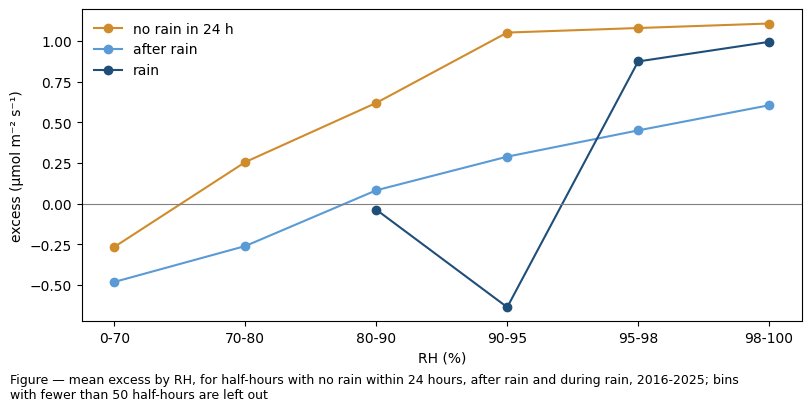

In [17]:
fig, ax = plt.subplots(figsize=(8, 4), layout='constrained')
_x = np.arange(len(rh_mean))
for _col, _c in zip(rh_mean.columns, ['#d08c2c', '#5b9bd5', '#1f4e79']):
    _ok = rh_n[_col].reindex(rh_mean.index) >= 50
    ax.plot(_x[_ok], rh_mean[_col][_ok], marker='o', color=_c, label=_col)
ax.axhline(0, color='0.5', lw=0.8)
ax.set_xticks(_x, [f"{i.left:.0f}-{min(i.right, 100):.0f}" for i in rh_mean.index])
ax.set_xlabel('RH (%)')
ax.set_ylabel('excess (µmol m⁻² s⁻¹)')
ax.legend(frameon=False)
figcap(fig, "mean excess by RH, for half-hours with no rain within 24 hours, after rain and during rain, "
            "2016-2025; bins with fewer than 50 half-hours are left out")
plt.show()

## 📋 Table: excess as a linear function of the conditions

In [18]:
_s = dn.dropna(subset=['ex', 'RH', 'cloud', 'USTAR', 'ZL', 'TA'])
_s = _s[_s['ZL'].between(-2, 2)]
_X = pd.DataFrame({'intercept': 1.0, 'rain': (_s['cls'] == 'rain').astype(float),
                   'after rain': (_s['cls'] == 'after rain').astype(float), 'RH (per 10 %)': _s['RH'] / 10,
                   'cloudiness': _s['cloud'], 'USTAR (m s-1)': _s['USTAR'], 'ZL': _s['ZL'], 'TA (°C)': _s['TA']})
_models = {'rain only': ['intercept', 'rain', 'after rain'],
           '+ RH': ['intercept', 'rain', 'after rain', 'RH (per 10 %)'],
           '+ cloudiness, USTAR, ZL, TA': list(_X.columns)}
_rows = {}
for _name, _cols in _models.items():
    _b, _res, *_ = np.linalg.lstsq(_X[_cols].to_numpy(), _s['ex'].to_numpy(), rcond=None)
    _rows[_name] = pd.Series(_b, index=_cols)
    _rows[_name]['R²'] = 1 - _res[0] / ((_s['ex'] - _s['ex'].mean()) ** 2).sum()
_t = pd.DataFrame(_rows).reindex(list(_X.columns) + ['R²'])
display(styled(_t, caption=f"least-squares coefficients of the excess (µmol m⁻² s⁻¹) on the rain classes "
                           f"and the conditions, {len(_s):,} night half-hours with ZL between -2 and 2",
               fmt="{:.3f}", cmap=None))

Table — least-squares coefficients of the excess (µmol m⁻² s⁻¹) on the rain classes and the
conditions, 17,261 night half-hours with ZL between -2 and 2



,rain only,+ RH,"+ cloudiness, USTAR, ZL, TA"
intercept,0.320,-2.302,-4.021
rain,0.564,-0.276,-0.289
after rain,0.001,-0.577,-0.555
RH (per 10 %),-,0.352,0.496
cloudiness,-,-,-1.868
USTAR (m s-1),-,-,2.198
ZL,-,-,4.802
TA (°C),-,-,0.030
R²,0.003,0.019,0.043


## 📋 Table: excess of rain and after-rain half-hours by event and soil

In [19]:
_w = dn[dn['cls'].isin(['rain', 'after rain'])]
_parts = {
    'event amount (mm)': _w.groupby(pd.cut(_w['event_mm'], [0, 1, 5, 15, 40, 1e3]), observed=True)['ex'],
    'days without rain before': _w.groupby(pd.cut(_w['days_dry_before'], [0, 1, 3, 7, 14, 1e3]), observed=True)['ex'],
    'soil water content 5 cm (%)': _w.groupby(pd.qcut(_w['SWC_5CM'], 5, precision=0), observed=True)['ex'],
}
_t = pd.concat({k: g.agg(['size', 'mean', 'median']) for k, g in _parts.items()})
_t.index = [f"{a}: {b}" for a, b in _t.index]
display(styled(_t.rename(columns={'size': 'n'}), caption="excess of the rain and after-rain half-hours by the "
                                                        "amount of the event, the days without rain before "
                                                        "it, and the soil water content (quintiles), in "
                                                        "µmol m⁻² s⁻¹", fmt={'n': "{:.0f}"},
               subset=['mean', 'median']))

Table — excess of the rain and after-rain half-hours by the amount of the event, the days without
rain before it, and the soil water content (quintiles), in µmol m⁻² s⁻¹



,n,mean,median
"event amount (mm): (0.0, 1.0]",3635,0.29,-0.15
"event amount (mm): (1.0, 5.0]",2748,0.59,-0.09
"event amount (mm): (5.0, 15.0]",2160,0.48,-0.05
"event amount (mm): (15.0, 40.0]",911,1.08,0.21
"event amount (mm): (40.0, 1000.0]",93,0.36,0.06
"days without rain before: (0.0, 1.0]",6787,0.38,-0.14
"days without rain before: (1.0, 3.0]",1869,0.68,0.03
"days without rain before: (3.0, 7.0]",575,0.94,0.21
"days without rain before: (7.0, 14.0]",265,0.96,0.57
"days without rain before: (14.0, 1000.0]",51,0.83,-0.14


## 📋 Table: excess per month and class

In [20]:
_t = dn.pivot_table(index=dn.index.month, columns='cls', values='ex', aggfunc='mean', observed=True)[CLASSES]
_t.index.name = 'month'
display(styled(_t, caption="mean excess per month and class, in µmol m⁻² s⁻¹, 2016-2025"))

Table — mean excess per month and class, in µmol m⁻² s⁻¹, 2016-2025



cls,dry,humid,fog/dew,after rain,rain
month,,,,,
1,-0.02,0.34,-0.02,0.04,0.02
2,0.12,0.15,1.01,0.77,0.52
3,0.03,0.33,0.81,0.18,0.93
4,0.12,0.19,-2.74,0.08,0.74
5,-0.04,0.42,1.77,0.04,0.18
6,0.17,2.09,7.90,0.49,1.87
7,0.08,3.82,-,0.02,1.94
8,-0.05,1.54,8.00,1.28,1.76
9,0.09,1.96,2.71,0.37,1.37


## 📋 Table: excess by USTAR and class

In [21]:
_m, _n = binned(dn, 'USTAR', [0, 0.4, 0.5, 0.6, 0.8, 1.0, 3.0])
_t = _m[CLASSES].join(_n[CLASSES].sum(axis=1).rename('n'))
display(styled(_t, caption="mean excess by USTAR and class, in µmol m⁻² s⁻¹; USTAR is above the CUT_50 "
                           "threshold in every half-hour", fmt={**{c: "{:.2f}" for c in CLASSES}, 'n': "{:.0f}"},
               subset=CLASSES))

Table — mean excess by USTAR and class, in µmol m⁻² s⁻¹; USTAR is above the CUT_50 threshold in
every half-hour



,dry,humid,fog/dew,after rain,rain,n
USTAR,,,,,,
"(0.5, 0.6]",-1.27,0.26,0.68,-0.14,1.11,3754
"(0.6, 0.8]",-0.32,0.57,0.75,0.19,0.75,7272
"(0.8, 1.0]",0.74,2.11,1.53,0.63,0.76,4050
"(1.0, 3.0]",1.85,1.66,1.99,0.69,0.96,3556


No pulse after rain is visible. During rain the excess is about constant over the event. After rain
it depends on RH: with RH below 90 % it is negative for 6 hours and then about zero; at 98 % and
above it is 0.3-1.7 from the first hours to more than 4 days after rain. RH is the strongest single
predictor. In the linear model it takes over most of the effect of rain, and cloudiness, `USTAR`,
`ZL` and `TA` do not remove it; the half-hourly scatter is large (R² below 0.1). The excess also
rises with `USTAR` in every class but rain, the dry nights included (-1.3 at 0.5-0.6 m s⁻¹, +1.9
above 1 m s⁻¹). Up to 0.8 m s⁻¹ the wet classes lie above the dry class at the same `USTAR`; above
0.8 m s⁻¹ the dry class reaches the after-rain and rain classes, and above 1 m s⁻¹ the humid class
as well.

</br>

# 3. Turbulent flux or storage

`NEE` is the turbulent flux `FC` plus the storage term `SC` (`SC_SINGLE`, gap-filled at Level 3.1).
Flushing of CO2 stored in the canopy air at the end of a calm, wet spell would show as a negative
storage term and a high turbulent flux in the first half-hours after a calm spell.

## 📋 Table: excess split into turbulent flux and storage

In [22]:
_ym = dn.index.to_period('M')
_ref = dn[dn['cls'] == 'dry'].groupby(_ym[dn['cls'] == 'dry'])[['FC_turb', SC]].mean()
_anom = dn[['FC_turb', SC]] - _ref.reindex(_ym).to_numpy()
_fc_ex = (dn_all['FC_turb'] - dry_reference(dn_all, 'FC_turb'))[dn_all[NEE].notna()]
_t = pd.DataFrame({'excess of NEE': dn.groupby('cls', observed=True)['ex'].mean(),
                   'excess of FC alone': _fc_ex.groupby(dn['cls'], observed=True).mean(),
                   'FC against dry nights of the month': _anom['FC_turb'].groupby(dn['cls'], observed=True).mean(),
                   'SC against dry nights of the month': _anom[SC].groupby(dn['cls'], observed=True).mean(),
                   'SC': dn.groupby('cls', observed=True)[SC].mean()}).reindex(CLASSES)
display(styled(_t, caption="excess of NEE and of the turbulent flux FC alone (FC against its own dry-night "
                           "reference), and the mean FC and SC against the dry nights of the same month, in "
                           "µmol m⁻² s⁻¹"))

Table — excess of NEE and of the turbulent flux FC alone (FC against its own dry-night reference),
and the mean FC and SC against the dry nights of the same month, in µmol m⁻² s⁻¹



,excess of NEE,excess of FC alone,FC against dry nights of the month,SC against dry nights of the month,SC
cls,,,,,
dry,0.07,0.07,0.00,0.00,0.27
humid,1.06,1.04,0.40,0.03,0.10
fog/dew,1.11,1.18,0.36,-0.07,-0.06
after rain,0.30,0.38,-0.41,-0.02,0.06
rain,0.87,1.02,0.50,-0.12,0.04


## 📋 Table: excess after calm spells

In [23]:
_t = dn.pivot_table(index='cls', columns='calm_before', values='ex', aggfunc=['mean', 'size'], observed=True).reindex(CLASSES)
_t.columns = ['mean, no calm before', 'mean, calm before', 'n, no calm before', 'n, calm before']
display(styled(_t, caption="mean excess in µmol m⁻² s⁻¹ with and without a USTAR failure (CUT_50) in the "
                           "2 hours before", fmt={**{c: "{:.2f}" for c in _t.columns[:2]}, **{c: "{:.0f}" for c in _t.columns[2:]}},
               subset=list(_t.columns[:2])))

Table — mean excess in µmol m⁻² s⁻¹ with and without a USTAR failure (CUT_50) in the 2 hours before



,"mean, no calm before","mean, calm before","n, no calm before","n, calm before"
cls,,,,
dry,0.68,-0.57,3409,3238
humid,0.97,1.17,782,637
fog/dew,1.18,1.02,560,463
after rain,0.36,0.22,3559,2725
rain,0.56,1.42,2075,1188


The excess sits in the turbulent flux. The storage term is 0.0 to 0.1 µmol m⁻² s⁻¹ lower on wet
nights than on the dry nights of the same month. After a calm spell the excess is lower in the dry,
fog/dew and after-rain classes, but higher on humid nights (1.17 against 0.97) and during rain
(1.42 against 0.56). Flushing of stored CO2 is not the main cause; during rain it may contribute.

</br>

# 4. Sonic anemometer

Water on the transducers of the sonic would distort the vertical wind and the sonic temperature and
affect every flux. `SONIC_DIAG_NREX` is 0 in every half-hour and is not used. Night-time `H` is
normally negative; strongly positive `H` at night and the steady-state test of `H` (`H_SSITC_TEST`)
are the signs used here, with the spike counts of `W` and `T_SONIC`.

## 📋 Table: sonic diagnostics per class

In [24]:
dn['TS_minus_TA'] = dn['T_SONIC'] - dn['TA']
_t = pd.DataFrame({
    'H median (W m-2)': dn.groupby('cls', observed=True)['H'].median(),
    'H 95th percentile (W m-2)': dn.groupby('cls', observed=True)['H'].quantile(0.95),
    'H > 10 W m-2 (%)': dn['H'].gt(10).groupby(dn['cls'], observed=True).mean() * 100,
    'H_SSITC_TEST = 2 (%)': dn['H_SSITC_TEST'].eq(2).groupby(dn['cls'], observed=True).mean() * 100,
    'W spikes': dn.groupby('cls', observed=True)['W_NUM_SPIKES'].mean(),
    'T_SONIC spikes': dn.groupby('cls', observed=True)['T_SONIC_NUM_SPIKES'].mean(),
    'T_SONIC - TA (K)': dn.groupby('cls', observed=True)['TS_minus_TA'].median(),
}).reindex(CLASSES)
display(styled(_t, caption="night-time H, its steady-state flag, the spike counts per half-hour and the "
                           "difference of sonic and air temperature per class, for the half-hours with NEE",
               fmt="{:.1f}", cmap=None))

Table — night-time H, its steady-state flag, the spike counts per half-hour and the difference of
sonic and air temperature per class, for the half-hours with NEE



,H median (W m-2),H 95th percentile (W m-2),H > 10 W m-2 (%),H_SSITC_TEST = 2 (%),W spikes,T_SONIC spikes,T_SONIC - TA (K)
cls,,,,,,,
dry,-46.0,10.9,5.2,5.5,0.4,29.1,3.4
humid,-18.3,49.4,16.2,10.8,0.4,33.8,7.0
fog/dew,-8.4,133.5,24.4,19.6,1.2,48.0,9.0
after rain,-26.3,48.1,12.5,9.5,0.6,28.9,5.8
rain,-28.5,183.8,19.3,14.1,2.1,58.5,4.5


## 📋 Table: excess after leaving out suspicious sonic half-hours

In [25]:
_sp = (dn['W_NUM_SPIKES'] <= dn['W_NUM_SPIKES'].median()) & (dn['T_SONIC_NUM_SPIKES'] <= dn['T_SONIC_NUM_SPIKES'].median())
_screens = {'all': pd.Series(True, index=dn.index), 'H ≤ 10 W m-2': dn['H'] <= 10, 'H ≤ 0': dn['H'] <= 0,
            'H_SSITC_TEST < 2': dn['H_SSITC_TEST'] < 2,
            'H ≤ 10, H_SSITC_TEST < 2, spikes ≤ median': (dn['H'] <= 10) & (dn['H_SSITC_TEST'] < 2) & _sp}
_t = pd.DataFrame({k: dn[m].groupby('cls', observed=True)['ex'].mean() for k, m in _screens.items()}).reindex(CLASSES).T
_t['rain - dry'] = _t['rain'] - _t['dry']
_t['fog/dew - dry'] = _t['fog/dew'] - _t['dry']
display(styled(_t, caption="mean excess per class in µmol m⁻² s⁻¹ after each screen of the sonic, and the "
                           "difference of the rain and fog/dew classes to the dry class"))

Table — mean excess per class in µmol m⁻² s⁻¹ after each screen of the sonic, and the difference of
the rain and fog/dew classes to the dry class



cls,dry,humid,fog/dew,after rain,rain,rain - dry,fog/dew - dry
all,0.07,1.06,1.11,0.30,0.87,0.80,1.04
H ≤ 10 W m-2,0.12,1.19,1.52,0.34,0.80,0.68,1.40
H ≤ 0,0.15,1.37,1.66,0.31,0.73,0.58,1.51
H_SSITC_TEST < 2,0.13,1.20,1.14,0.27,0.81,0.68,1.01
"H ≤ 10, H_SSITC_TEST < 2, spikes ≤ median",-0.37,0.64,1.38,-0.03,0.59,0.95,1.75


## 📋 Table: excess by the anomaly of sonic minus air temperature

In [26]:
dn['TS_anom'] = dn['TS_minus_TA'] - dn.groupby(dn.index.to_period('M'))['TS_minus_TA'].transform('median')
_t = pd.DataFrame({cl: dn[dn['cls'] == cl].groupby(pd.qcut(dn.loc[dn['cls'] == cl, 'TS_anom'], 5, labels=False))['ex'].mean()
                   for cl in CLASSES})
_t.index = ['lowest fifth', 'second', 'third', 'fourth', 'highest fifth']
_t.index.name = 'T_SONIC - TA'
display(styled(_t, caption="mean excess in µmol m⁻² s⁻¹ per fifth of the difference of sonic and air "
                           "temperature (against its monthly median), per class. A wet sonic would read a "
                           "different temperature and, if it distorts the flux, show a trend along the rows"))

Table — mean excess in µmol m⁻² s⁻¹ per fifth of the difference of sonic and air temperature
(against its monthly median), per class. A wet sonic would read a different temperature and, if it
distorts the flux, show a trend along the rows



,dry,humid,fog/dew,after rain,rain
T_SONIC - TA,,,,,
lowest fifth,-0.24,1.48,1.75,0.00,0.52
second,0.04,1.31,1.35,0.38,0.75
third,0.21,1.33,1.96,0.23,1.00
fourth,0.02,1.21,0.62,0.19,1.20
highest fifth,0.32,-0.29,-0.05,0.70,0.90


On wet nights, most of all in rain and fog, `H` is more often positive, its steady-state test fails
more often and the sonic reads up to 9 K above the air temperature. These are signs of a wet sonic.
The excess does not depend on them in a simple way: after each screen the rain class remains 0.6 to
1.0 µmol m⁻² s⁻¹ and the fog/dew class 1.0 to 1.8 above the dry class. Within a class the excess
shows no consistent trend with the sonic temperature: it falls in the humid class and rises
somewhat in the rain and after-rain classes.

</br>

# 5. LI-7200 signal strength and flow

Water in the intake tube or on the optics of the LI-7200 lowers its signal strength. An artefact of
the analyser would grow as the signal strength or the flow drops.

## 📋 Table: excess by signal strength and class

In [27]:
_m, _n = binned(dn, 'CUSTOM_SIGNAL_STRENGTH_IRGA72_MEAN', [0, 80, 85, 90, 95, 101])
_t = _m[CLASSES].join(_n[CLASSES].add_prefix('n, '))
_t.index = ['below 80 %', '80-85 %', '85-90 %', '90-95 %', '95 % and above']
display(styled(_t, caption="mean excess by the signal strength of the LI-7200 and class, in µmol m⁻² s⁻¹, "
                           "and the number of half-hours",
               fmt={**{c: "{:.2f}" for c in CLASSES}, **{f'n, {c}': "{:.0f}" for c in CLASSES}}, subset=CLASSES))

Table — mean excess by the signal strength of the LI-7200 and class, in µmol m⁻² s⁻¹, and the number
of half-hours



cls,dry,humid,fog/dew,after rain,rain,"n, dry","n, humid","n, fog/dew","n, after rain","n, rain"
below 80 %,1.24,4.07,2.87,0.78,1.44,62,87,83,424,372
80-85 %,0.04,1.70,2.87,0.67,1.40,667,82,78,503,312
85-90 %,0.10,1.17,1.64,0.63,1.01,1054,185,139,967,587
90-95 %,0.11,0.77,0.83,0.13,1.11,1935,477,429,1747,681
95 % and above,0.03,0.96,0.64,0.15,0.39,2929,588,294,2643,1311


## 📋 Table: excess by flow and class

In [28]:
_t = pd.DataFrame({cl: dn[dn['cls'] == cl].groupby(pd.qcut(dn.loc[dn['cls'] == cl, 'CUSTOM_FLOW_VOLRATE_MEAN'], 5, labels=False))['ex'].mean()
                   for cl in CLASSES})
_t.index = ['lowest fifth', 'second', 'third', 'fourth', 'highest fifth']
_t.index.name = 'flow'
_s = dn[dn['cls'].isin(['fog/dew', 'after rain', 'rain'])].dropna(subset=['ex', 'CUSTOM_SIGNAL_STRENGTH_IRGA72_MEAN', 'CUSTOM_FLOW_VOLRATE_MEAN'])
_b = np.linalg.lstsq(np.column_stack([np.ones(len(_s)), _s['CUSTOM_SIGNAL_STRENGTH_IRGA72_MEAN'], _s['CUSTOM_FLOW_VOLRATE_MEAN']]),
                     _s['ex'].to_numpy(), rcond=None)[0]
display(styled(_t, caption=f"mean excess per fifth of the flow of the LI-7200 (within each class), in µmol m⁻² "
                           f"s⁻¹. On the fog/dew, after-rain and rain half-hours together, the excess changes by "
                           f"{_b[1]:+.3f} µmol m⁻² s⁻¹ per % of signal strength and {_b[2]:+.3f} per l min⁻¹ "
                           f"of flow (least squares)"))

Table — mean excess per fifth of the flow of the LI-7200 (within each class), in µmol m⁻² s⁻¹. On
the fog/dew, after-rain and rain half-hours together, the excess changes by -0.036 µmol m⁻² s⁻¹ per
% of signal strength and +0.022 per l min⁻¹ of flow (least squares)



,dry,humid,fog/dew,after rain,rain
flow,,,,,
lowest fifth,0.12,0.69,1.54,0.39,0.59
second,0.15,0.16,0.60,0.52,0.59
third,0.41,0.96,0.95,-0.01,0.33
fourth,-0.28,1.13,1.72,0.22,1.67
highest fifth,-0.04,2.24,0.84,0.40,1.16


Below 80 % signal strength the excess of the rain and fog/dew half-hours is 1.0 and 2.2 µmol m⁻² s⁻¹
higher than at 95 % and above, where it is 0.4 and 0.6. A drop of 10 % in signal strength adds about
0.4. The flow has no effect. An effect of the analyser can explain part of the excess, during rain
up to about half; at full signal an excess remains in every wet class.

</br>

# 6. Overlap with the LI-7500, 2016-2017

Half-hour pairs of the turbulent flux of the LI-7200 after Level 2 (`FC_L2_QCF`) and the corrected
flux of the LI-7500 after the open-path correction (`FC_L1.1_OPCO`, steady-state flag below 2), on
the night half-hours of the LI-7200 with `NEE` after Level 3.3. The excess of the LI-7500 is its
flux measured against the same dry-night reference, that is the excess of the LI-7200 minus the
difference of the two. Both analysers share one sonic, so this check cannot detect a fault of the
sonic.

## 📋 Table: LI-7200 against LI-7500 per class and AGC

In [29]:
_j = dn.loc['2016':'2017'].join(o75.add_suffix('_75'), how='inner')
_j = _j[_j[FC_L2].notna() & _j['FC_L1.1_OPCO_75'].notna() & (_j['FC_SSITC_TEST_75'] < 2)].copy()
_j['AGC'] = np.where(_j['CUSTOM_AGC_IRGA75_MEAN_75'] <= AGC_LIMIT, f'≤ {AGC_LIMIT}', f'> {AGC_LIMIT}')
_j['diff'] = _j[FC_L2] - _j['FC_L1.1_OPCO_75']
_j['ex75'] = _j['ex'] - _j['diff']
_g = _j.groupby(['cls', 'AGC'], observed=True)
_t = pd.DataFrame({'n': _g.size(), 'FC LI-7200': _g[FC_L2].mean(), 'FC LI-7500': _g['FC_L1.1_OPCO_75'].mean(),
                   'difference, median': _g['diff'].median(), 'excess LI-7200': _g['ex'].mean(),
                   'excess LI-7500': _g['ex75'].mean(),
                   'correlation': _g.apply(lambda x: x[FC_L2].corr(x['FC_L1.1_OPCO_75']) if len(x) > 10 else np.nan)})
_t = _t.reindex(CLASSES, level=0)
display(styled(_t, caption="pairs of the LI-7200 and the corrected LI-7500 on the night half-hours of "
                           "2016-2017 per class and AGC of the LI-7500: mean fluxes, median difference "
                           "(LI-7200 minus LI-7500), mean excess of each over the dry-night reference of the "
                           "LI-7200, in µmol m⁻² s⁻¹, and the correlation of the pairs",
               fmt={'n': "{:.0f}"}, cmap=None))

Table — pairs of the LI-7200 and the corrected LI-7500 on the night half-hours of 2016-2017 per
class and AGC of the LI-7500: mean fluxes, median difference (LI-7200 minus LI-7500), mean excess of
each over the dry-night reference of the LI-7200, in µmol m⁻² s⁻¹, and the correlation of the pairs



On dry nights the two analysers agree half-hour by half-hour (correlation 0.90, median difference
-0.2). On humid nights, where the LI-7500 is clean, it also measures an excess (1.0, against 0.7 of
the LI-7200 on the same half-hours), with more scatter (correlation 0.64). After rain neither shows
an excess on these half-hours (-0.2 and -0.3). On fog/dew nights the LI-7500 does not follow the
LI-7200: its flux is close to zero, 1.1 below the LI-7200 in the median, with a correlation of 0.3.
Fog/dew nights are mostly cold (mean `TA` 0.7 °C over 2016-2025), where the self-heating
correction of the LI-7500 is largest. During rain only 7 pairs remain.

</br>

# Conclusion and open points

**Is the excess real?** Most likely yes, as a flux, but it is not a pulse of respiration after
rain. It appears in most years, sits in the turbulent flux, follows air humidity rather than rain,
is explained only in part by the signal strength of the LI-7200 and not by screens of the sonic,
and the clean LI-7500 half-hours show it on humid nights. Respiration of litter, moss and bark
that rain, dew and fog keep wet would fit this pattern. Two points remain open: a fault of the
sonic that both analysers share, and whether the clear, dry nights of the reference are themselves
too low. The rise of the excess with `USTAR` on dry nights points to the second for part of it.

**For the next step.** An uplift for the missing wet nights of the LI-7500 years would be learned
on RH and season, not on the time since rain. Its size depends on the reference by a factor of
about 0.4 to 1.7, so the spread of the references belongs in its uncertainty. A validation in the
overlap rests on the humid and after-rain nights; the fog/dew nights cannot be validated with the
LI-7500.

**Open**

- Independent respiration data for CH-LAE (soil chambers or others), to test the size of the
  wet-night flux.
- 2026: the merged meteo has no precipitation after 2025, so 2026 is not analysed.
- The rise of the night `NEE` with `USTAR` above the threshold on dry nights.

</br>

# End of notebook

In [30]:
_dt = datetime.now() - NOTEBOOK_START
print(f"Finished {datetime.now():%Y-%m-%d %H:%M:%S}; runtime {_dt.total_seconds() / 60:.1f} min")

Finished 2026-11-04 17:34:53; runtime 0.1 min
